In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
os.environ['KAGGLE_CONFIG_DIR'] = "/content/drive/MyDrive/MAHNOB-HCI"

In [ ]:
%cd /content/drive/MyDrive/MAHNOB-HCI/

/content/drive/MyDrive/MAHNOB-HCI


Logits shape: torch.Size([2, 5])


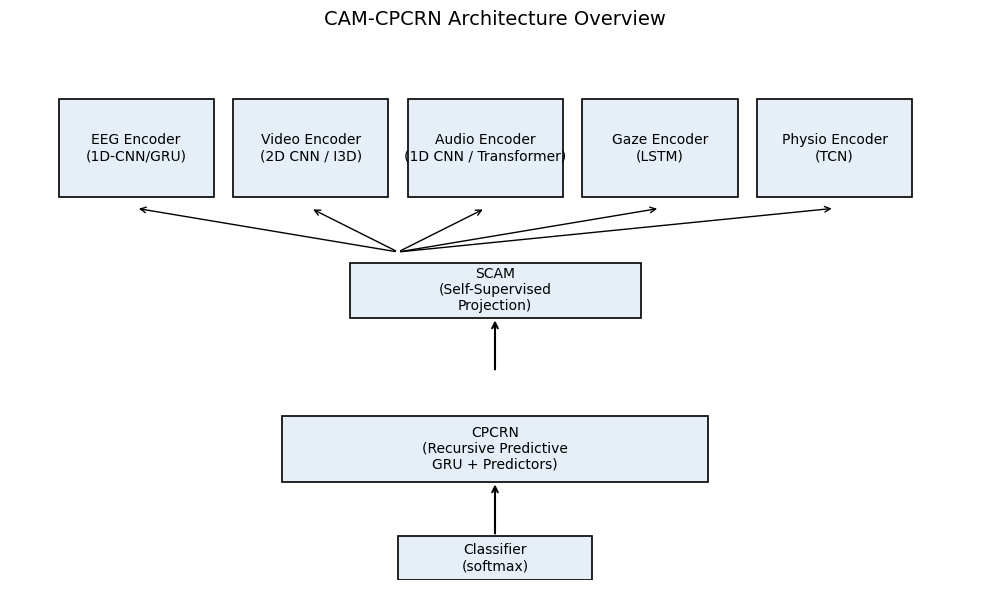

In [ ]:
# cam_cpcrn.py
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# -------------------------
# Modality encoders (lightweight)
# -------------------------
class EEGEncoder(nn.Module):
    def __init__(self, in_ch=32, emb_dim=128, kernel_size=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(in_ch, 64, kernel_size, padding=kernel_size//2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Conv1d(64, emb_dim, kernel_size, padding=kernel_size//2),
            nn.AdaptiveAvgPool1d(1), # collapse time-window -> vector
        )
    def forward(self, x): # x: (B, C_eeg, T_win)
        v = self.net(x).squeeze(-1)
        return v  # (B, emb_dim)

class VideoEncoder(nn.Module):
    def __init__(self, in_ch=3, emb_dim=256):
        super().__init__()
        # very small 3D-ish encoder approximated with 2D + temporal pooling for simplicity
        self.cnn = nn.Sequential(
            nn.Conv2d(in_ch, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1,1)),
        )
        self.fc = nn.Linear(64, emb_dim)
    def forward(self, frame): # frame: (B, C, H, W) for a representative frame / precomputed frame embedding
        x = self.cnn(frame).view(frame.size(0), -1)
        return self.fc(x)

class AudioEncoder(nn.Module):
    def __init__(self, in_ch=1, emb_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(in_ch, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv1d(32, 64, 3, padding=1),
            nn.AdaptiveAvgPool1d(1),
        )
        self.fc = nn.Linear(64, emb_dim)
    def forward(self, x): # (B, C_audio, T_audio)
        x = self.net(x).squeeze(-1)
        return self.fc(x)

class GazeEncoder(nn.Module):
    def __init__(self, in_dim=2, emb_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64),
            nn.ReLU(),
            nn.Linear(64, emb_dim)
        )
    def forward(self, x): # (B, in_dim)
        return self.net(x)

class PhysioEncoder(nn.Module):
    def __init__(self, in_ch=4, emb_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(in_ch, 32, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(32, emb_dim)
        )
    def forward(self, x): # (B, C_phys, T)
        return self.net(x)

# -------------------------
# SCAM projection head
# -------------------------
class ProjectionHead(nn.Module):
    def __init__(self, in_dim, proj_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, in_dim),
            nn.ReLU(),
            nn.Linear(in_dim, proj_dim)
        )
    def forward(self, x):
        x = self.net(x)
        return F.normalize(x, dim=-1)

# -------------------------
# CPCRN: recursive predictive module
# -------------------------
class CPCRN(nn.Module):
    def __init__(self, latent_dim=128, hidden_dim=256, num_layers=1):
        super().__init__()
        # a GRU-based recurrent core for z* state updates
        self.gru = nn.GRU(latent_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.state_proj = nn.Linear(hidden_dim, latent_dim)  # project back to latent space
        # predictors m -> n will be created dynamically (see wrapper)
    def forward(self, z_seq, h0=None):
        # z_seq: (B, T, latent_dim) aligned latent over time (e.g., fused or concatenated tokens)
        out, hn = self.gru(z_seq, h0)
        z_hat = self.state_proj(out)  # (B, T, latent_dim) predictions of "next" latent (shift training wise)
        return z_hat, hn

# -------------------------
# Full CAM-CPCRN wrapper
# -------------------------
class CAM_CPCRN(nn.Module):
    def __init__(self,
                 emb_dims = {"EEG":128, "VID":256, "AUD":128, "GAZE":64, "PHYS":64},
                 proj_dim=128,
                 latent_dim=128,
                 hidden_dim=256,
                 num_classes=5):
        super().__init__()
        # Encoders
        self.encoders = nn.ModuleDict({
            "EEG": EEGEncoder(in_ch=32, emb_dim=emb_dims["EEG"]),
            "VID": VideoEncoder(in_ch=3, emb_dim=emb_dims["VID"]),
            "AUD": AudioEncoder(in_ch=1, emb_dim=emb_dims["AUD"]),
            "GAZE": GazeEncoder(in_dim=2, emb_dim=emb_dims["GAZE"]),
            "PHYS": PhysioEncoder(in_ch=4, emb_dim=emb_dims["PHYS"]),
        })
        # modality-specific projectors (SCAM)
        self.proj = nn.ModuleDict({
            m: ProjectionHead(in_dim=emb_dims[m], proj_dim=proj_dim) for m in emb_dims.keys()
        })
        # fusion projector (to latent space)
        self.fusion = nn.Linear(len(emb_dims)*proj_dim, latent_dim)
        # CPCRN core
        self.cpcrn = CPCRN(latent_dim=latent_dim, hidden_dim=hidden_dim)
        # modality predictors: predict other modality latents from fused latent
        self.predictors = nn.ModuleDict()
        for source in emb_dims.keys():
            for target in emb_dims.keys():
                if source==target: continue
                self.predictors[f"{source}_to_{target}"] = nn.Sequential(
                    nn.Linear(proj_dim, proj_dim),
                    nn.ReLU(),
                    nn.Linear(proj_dim, proj_dim)
                )
        # classifier head
        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, latent_dim//2),
            nn.ReLU(),
            nn.Linear(latent_dim//2, num_classes)
        )

    def encode_modal(self, batch):
        """
        batch: dict with keys ["EEG","VID","AUD","GAZE","PHYS"]
        expected shapes:
         - EEG: (B, C_eeg=32, T_win)
         - VID: (B, C, H, W)  (representative frame or precomputed embedding)
         - AUD: (B, C_audio=1, T_audio)
         - GAZE: (B, 2)
         - PHYS: (B, C_phys=4, T_phys)
        """
        embs = {}
        for m, enc in self.encoders.items():
            embs[m] = enc(batch[m])
        return embs

    def forward(self, batch):
        # encode
        embs = self.encode_modal(batch)
        # project (SCAM)
        proj = {m: self.proj[m](embs[m]) for m in embs.keys()}  # normalized embeddings
        # create fused latent token by concatenation (simple fusion; replace with attention if desired)
        fused = torch.cat([proj[m] for m in sorted(proj.keys())], dim=-1)  # (B, num_mod*proj_dim)
        z0 = self.fusion(fused).unsqueeze(1)  # (B, 1, latent_dim) single time-step sequence example
        # CPCRN predicts sequence (we demonstrate single-step predict; in practice pass T sequence)
        z_hat_seq, _ = self.cpcrn(z0)  # (B, 1, latent_dim)
        z_hat = z_hat_seq.squeeze(1)  # (B, latent_dim)

        # classification
        logits = self.classifier(z_hat)

        # cross-modal predictions example: source proj -> predict target proj
        cross_preds = {}
        for key, pred in self.predictors.items():
            s, _, t = key.partition("_to_")
            cross_preds[key] = pred(proj[s])  # (B, proj_dim)
        return {
            "logits": logits,
            "proj": proj,
            "z_hat": z_hat,
            "cross_preds": cross_preds
        }

# -------------------------
# Loss functions: alignment (InfoNCE-style) + predictive MSE + classifier CE
# -------------------------
def info_nce_loss(proj_embeddings, temperature=0.1):
    # proj_embeddings: dict of modality->(B, D) normalized vectors
    # build positives as same-index across modalities
    modalities = sorted(proj_embeddings.keys())
    z_stack = torch.stack([proj_embeddings[m] for m in modalities], dim=1)  # (B, M, D)
    B, M, D = z_stack.shape
    z_flat = z_stack.view(B*M, D)  # (B*M, D)
    sim = torch.matmul(z_flat, z_flat.t()) / temperature  # (BM, BM)
    labels = torch.arange(B).unsqueeze(1).repeat(1, M).view(-1).to(z_flat.device) # naive
    # positive mask: same sample index but different mod -> many positives; here we form positives per sample
    # For simplicity we implement NT-Xent variant: for each (i,m) positive pairs are (i, n != m)
    mask = torch.eye(B, dtype=torch.bool).repeat_interleave(M, dim=0).to(z_flat.device)
    # For numerical stability zero out self-sim
    sim_exp = torch.exp(sim) * (~torch.eye(B*M, dtype=torch.bool).to(z_flat.device))
    # numerator: sum over positives (same sample, different modality)
    numerator = []
    for i in range(B):
        inds = [i*M + m for m in range(M)]
        # for each modality inside sample, numerator includes sum of exps with other modalities of same sample
        for m in range(M):
            idx = i*M + m
            pos_inds = [i*M + mm for mm in range(M) if mm!=m]
            numerator.append(sim_exp[idx, pos_inds].sum())
    numerator = torch.tensor(numerator, device=z_flat.device)
    denom = sim_exp.sum(dim=1)
    loss = -torch.log(numerator / denom + 1e-8).mean()
    return loss

def predictive_mse_loss(z_true, z_pred):
    # z_true, z_pred: (B, latent_dim)
    return F.mse_loss(z_pred, z_true)

# -------------------------
# Simple utility to draw architecture diagram using matplotlib
# -------------------------
def plot_architecture(savepath=None):
    fig, ax = plt.subplots(figsize=(10,6))
    ax.axis('off')

    # helper draw box
    def box(x,y,w,h, text, fontsize=10):
        rect = plt.Rectangle((x,y), w, h, fill=True, color='#E6EEF8', ec='k', lw=1.2)
        ax.add_patch(rect)
        ax.text(x+w/2, y+h/2, text, ha='center', va='center', fontsize=fontsize)

    # encoders row
    box(0.05,0.7,0.16,0.18, 'EEG Encoder\n(1D-CNN/GRU)')
    box(0.23,0.7,0.16,0.18, 'Video Encoder\n(2D CNN / I3D)')
    box(0.41,0.7,0.16,0.18, 'Audio Encoder\n(1D CNN / Transformer)')
    box(0.59,0.7,0.16,0.18, 'Gaze Encoder\n(LSTM)')
    box(0.77,0.7,0.16,0.18, 'Physio Encoder\n(TCN)')

    # arrows to SCAM
    ax.annotate('', xy=(0.13,0.68), xytext=(0.4,0.6), arrowprops=dict(arrowstyle='->'))
    ax.annotate('', xy=(0.31,0.68), xytext=(0.4,0.6), arrowprops=dict(arrowstyle='->'))
    ax.annotate('', xy=(0.49,0.68), xytext=(0.4,0.6), arrowprops=dict(arrowstyle='->'))
    ax.annotate('', xy=(0.67,0.68), xytext=(0.4,0.6), arrowprops=dict(arrowstyle='->'))
    ax.annotate('', xy=(0.85,0.68), xytext=(0.4,0.6), arrowprops=dict(arrowstyle='->'))

    # SCAM box
    box(0.35,0.48,0.3,0.1, 'SCAM\n(Self-Supervised\nProjection)')

    # arrow to CPCRN
    ax.annotate('', xy=(0.5,0.48), xytext=(0.5,0.38), arrowprops=dict(arrowstyle='->', lw=1.5))

    # CPCRN box
    box(0.28,0.18,0.44,0.12, 'CPCRN\n(Recursive Predictive\nGRU + Predictors)')

    # arrow to classifier
    ax.annotate('', xy=(0.5,0.18), xytext=(0.5,0.08), arrowprops=dict(arrowstyle='->', lw=1.5))

    # classifier box
    box(0.4,0.0,0.2,0.08, 'Classifier\n(softmax)')

    ax.set_title('CAM-CPCRN Architecture Overview', fontsize=14)
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()

# -------------------------
# quick smoke test (optional)
# -------------------------
if __name__ == "__main__":
    device = torch.device('cpu')
    model = CAM_CPCRN().to(device)
    # fake batch
    B = 2
    batch = {
        "EEG": torch.randn(B, 32, 64),        # 64-sample window
        "VID": torch.randn(B, 3, 64, 64),     # single frame 64x64
        "AUD": torch.randn(B, 1, 160),        # audio segment
        "GAZE": torch.randn(B, 2),            # gaze XY
        "PHYS": torch.randn(B, 4, 64)         # physio channels
    }
    out = model(batch)
    print("Logits shape:", out["logits"].shape)
    plot_architecture()


Logits shape: torch.Size([2, 5])


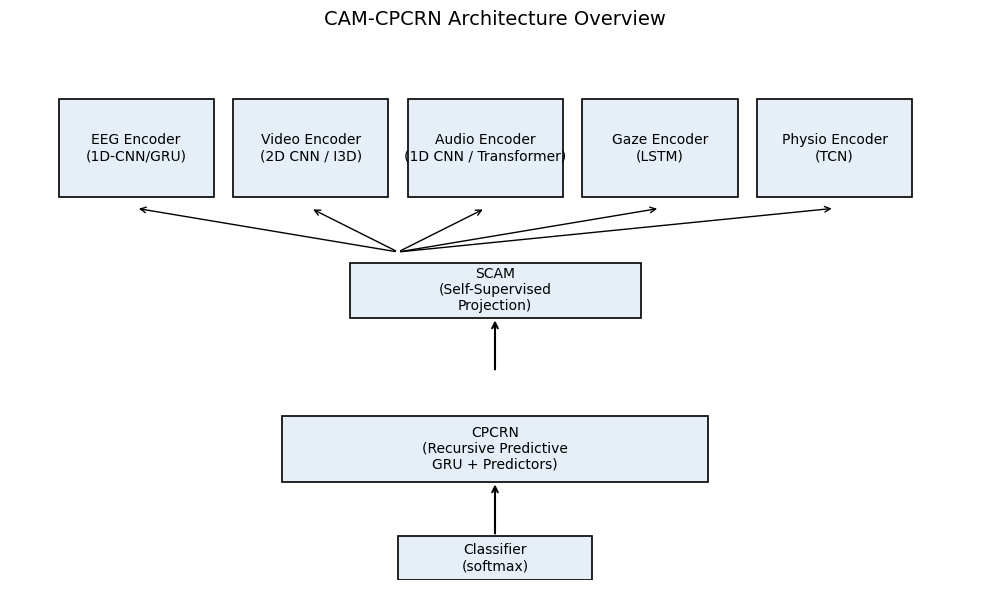

In [ ]:
# cam_cpcrn.py
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# -------------------------
# Modality encoders (lightweight)
# -------------------------
class EEGEncoder(nn.Module):
    def __init__(self, in_ch=32, emb_dim=128, kernel_size=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(in_ch, 64, kernel_size, padding=kernel_size//2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Conv1d(64, emb_dim, kernel_size, padding=kernel_size//2),
            nn.AdaptiveAvgPool1d(1), # collapse time-window -> vector
        )
    def forward(self, x): # x: (B, C_eeg, T_win)
        v = self.net(x).squeeze(-1)
        return v  # (B, emb_dim)

class VideoEncoder(nn.Module):
    def __init__(self, in_ch=3, emb_dim=256):
        super().__init__()
        # very small 3D-ish encoder approximated with 2D + temporal pooling for simplicity
        self.cnn = nn.Sequential(
            nn.Conv2d(in_ch, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1,1)),
        )
        self.fc = nn.Linear(64, emb_dim)
    def forward(self, frame): # frame: (B, C, H, W) for a representative frame / precomputed frame embedding
        x = self.cnn(frame).view(frame.size(0), -1)
        return self.fc(x)

class AudioEncoder(nn.Module):
    def __init__(self, in_ch=1, emb_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(in_ch, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv1d(32, 64, 3, padding=1),
            nn.AdaptiveAvgPool1d(1),
        )
        self.fc = nn.Linear(64, emb_dim)
    def forward(self, x): # (B, C_audio, T_audio)
        x = self.net(x).squeeze(-1)
        return self.fc(x)

class GazeEncoder(nn.Module):
    def __init__(self, in_dim=2, emb_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64),
            nn.ReLU(),
            nn.Linear(64, emb_dim)
        )
    def forward(self, x): # (B, in_dim)
        return self.net(x)

class PhysioEncoder(nn.Module):
    def __init__(self, in_ch=4, emb_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(in_ch, 32, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(32, emb_dim)
        )
    def forward(self, x): # (B, C_phys, T)
        return self.net(x)

# -------------------------
# SCAM projection head
# -------------------------
class ProjectionHead(nn.Module):
    def __init__(self, in_dim, proj_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, in_dim),
            nn.ReLU(),
            nn.Linear(in_dim, proj_dim)
        )
    def forward(self, x):
        x = self.net(x)
        return F.normalize(x, dim=-1)

# -------------------------
# CPCRN: recursive predictive module
# -------------------------
class CPCRN(nn.Module):
    def __init__(self, latent_dim=128, hidden_dim=256, num_layers=1):
        super().__init__()
        # a GRU-based recurrent core for z* state updates
        self.gru = nn.GRU(latent_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.state_proj = nn.Linear(hidden_dim, latent_dim)  # project back to latent space
        # predictors m -> n will be created dynamically (see wrapper)
    def forward(self, z_seq, h0=None):
        # z_seq: (B, T, latent_dim) aligned latent over time (e.g., fused or concatenated tokens)
        out, hn = self.gru(z_seq, h0)
        z_hat = self.state_proj(out)  # (B, T, latent_dim) predictions of "next" latent (shift training wise)
        return z_hat, hn

# -------------------------
# Full CAM-CPCRN wrapper
# -------------------------
class CAM_CPCRN(nn.Module):
    def __init__(self,
                 emb_dims = {"EEG":128, "VID":256, "AUD":128, "GAZE":64, "PHYS":64},
                 proj_dim=128,
                 latent_dim=128,
                 hidden_dim=256,
                 num_classes=5):
        super().__init__()
        # Encoders
        self.encoders = nn.ModuleDict({
            "EEG": EEGEncoder(in_ch=32, emb_dim=emb_dims["EEG"]),
            "VID": VideoEncoder(in_ch=3, emb_dim=emb_dims["VID"]),
            "AUD": AudioEncoder(in_ch=1, emb_dim=emb_dims["AUD"]),
            "GAZE": GazeEncoder(in_dim=2, emb_dim=emb_dims["GAZE"]),
            "PHYS": PhysioEncoder(in_ch=4, emb_dim=emb_dims["PHYS"]),
        })
        # modality-specific projectors (SCAM)
        self.proj = nn.ModuleDict({
            m: ProjectionHead(in_dim=emb_dims[m], proj_dim=proj_dim) for m in emb_dims.keys()
        })
        # fusion projector (to latent space)
        self.fusion = nn.Linear(len(emb_dims)*proj_dim, latent_dim)
        # CPCRN core
        self.cpcrn = CPCRN(latent_dim=latent_dim, hidden_dim=hidden_dim)
        # modality predictors: predict other modality latents from fused latent
        self.predictors = nn.ModuleDict()
        for source in emb_dims.keys():
            for target in emb_dims.keys():
                if source==target: continue
                self.predictors[f"{source}_to_{target}"] = nn.Sequential(
                    nn.Linear(proj_dim, proj_dim),
                    nn.ReLU(),
                    nn.Linear(proj_dim, proj_dim)
                )
        # classifier head
        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, latent_dim//2),
            nn.ReLU(),
            nn.Linear(latent_dim//2, num_classes)
        )

    def encode_modal(self, batch):
        """
        batch: dict with keys ["EEG","VID","AUD","GAZE","PHYS"]
        expected shapes:
         - EEG: (B, C_eeg=32, T_win)
         - VID: (B, C, H, W)  (representative frame or precomputed embedding)
         - AUD: (B, C_audio=1, T_audio)
         - GAZE: (B, 2)
         - PHYS: (B, C_phys=4, T_phys)
        """
        embs = {}
        for m, enc in self.encoders.items():
            embs[m] = enc(batch[m])
        return embs

    def forward(self, batch):
        # encode
        embs = self.encode_modal(batch)
        # project (SCAM)
        proj = {m: self.proj[m](embs[m]) for m in embs.keys()}  # normalized embeddings
        # create fused latent token by concatenation (simple fusion; replace with attention if desired)
        fused = torch.cat([proj[m] for m in sorted(proj.keys())], dim=-1)  # (B, num_mod*proj_dim)
        z0 = self.fusion(fused).unsqueeze(1)  # (B, 1, latent_dim) single time-step sequence example
        # CPCRN predicts sequence (we demonstrate single-step predict; in practice pass T sequence)
        z_hat_seq, _ = self.cpcrn(z0)  # (B, 1, latent_dim)
        z_hat = z_hat_seq.squeeze(1)  # (B, latent_dim)

        # classification
        logits = self.classifier(z_hat)

        # cross-modal predictions example: source proj -> predict target proj
        cross_preds = {}
        for key, pred in self.predictors.items():
            s, _, t = key.partition("_to_")
            cross_preds[key] = pred(proj[s])  # (B, proj_dim)
        return {
            "logits": logits,
            "proj": proj,
            "z_hat": z_hat,
            "cross_preds": cross_preds
        }

# -------------------------
# Loss functions: alignment (InfoNCE-style) + predictive MSE + classifier CE
# -------------------------
def info_nce_loss(proj_embeddings, temperature=0.1):
    # proj_embeddings: dict of modality->(B, D) normalized vectors
    # build positives as same-index across modalities
    modalities = sorted(proj_embeddings.keys())
    z_stack = torch.stack([proj_embeddings[m] for m in modalities], dim=1)  # (B, M, D)
    B, M, D = z_stack.shape
    z_flat = z_stack.view(B*M, D)  # (B*M, D)
    sim = torch.matmul(z_flat, z_flat.t()) / temperature  # (BM, BM)
    labels = torch.arange(B).unsqueeze(1).repeat(1, M).view(-1).to(z_flat.device) # naive
    # positive mask: same sample index but different mod -> many positives; here we form positives per sample
    # For simplicity we implement NT-Xent variant: for each (i,m) positive pairs are (i, n != m)
    mask = torch.eye(B, dtype=torch.bool).repeat_interleave(M, dim=0).to(z_flat.device)
    # For numerical stability zero out self-sim
    sim_exp = torch.exp(sim) * (~torch.eye(B*M, dtype=torch.bool).to(z_flat.device))
    # numerator: sum over positives (same sample, different modality)
    numerator = []
    for i in range(B):
        inds = [i*M + m for m in range(M)]
        # for each modality inside sample, numerator includes sum of exps with other modalities of same sample
        for m in range(M):
            idx = i*M + m
            pos_inds = [i*M + mm for mm in range(M) if mm!=m]
            numerator.append(sim_exp[idx, pos_inds].sum())
    numerator = torch.tensor(numerator, device=z_flat.device)
    denom = sim_exp.sum(dim=1)
    loss = -torch.log(numerator / denom + 1e-8).mean()
    return loss

def predictive_mse_loss(z_true, z_pred):
    # z_true, z_pred: (B, latent_dim)
    return F.mse_loss(z_pred, z_true)

# -------------------------
# Simple utility to draw architecture diagram using matplotlib
# -------------------------
def plot_architecture(savepath=None):
    fig, ax = plt.subplots(figsize=(10,6))
    ax.axis('off')

    # helper draw box
    def box(x,y,w,h, text, fontsize=10):
        rect = plt.Rectangle((x,y), w, h, fill=True, color='#E6EEF8', ec='k', lw=1.2)
        ax.add_patch(rect)
        ax.text(x+w/2, y+h/2, text, ha='center', va='center', fontsize=fontsize)

    # encoders row
    box(0.05,0.7,0.16,0.18, 'EEG Encoder\n(1D-CNN/GRU)')
    box(0.23,0.7,0.16,0.18, 'Video Encoder\n(2D CNN / I3D)')
    box(0.41,0.7,0.16,0.18, 'Audio Encoder\n(1D CNN / Transformer)')
    box(0.59,0.7,0.16,0.18, 'Gaze Encoder\n(LSTM)')
    box(0.77,0.7,0.16,0.18, 'Physio Encoder\n(TCN)')

    # arrows to SCAM
    ax.annotate('', xy=(0.13,0.68), xytext=(0.4,0.6), arrowprops=dict(arrowstyle='->'))
    ax.annotate('', xy=(0.31,0.68), xytext=(0.4,0.6), arrowprops=dict(arrowstyle='->'))
    ax.annotate('', xy=(0.49,0.68), xytext=(0.4,0.6), arrowprops=dict(arrowstyle='->'))
    ax.annotate('', xy=(0.67,0.68), xytext=(0.4,0.6), arrowprops=dict(arrowstyle='->'))
    ax.annotate('', xy=(0.85,0.68), xytext=(0.4,0.6), arrowprops=dict(arrowstyle='->'))

    # SCAM box
    box(0.35,0.48,0.3,0.1, 'SCAM\n(Self-Supervised\nProjection)')

    # arrow to CPCRN
    ax.annotate('', xy=(0.5,0.48), xytext=(0.5,0.38), arrowprops=dict(arrowstyle='->', lw=1.5))

    # CPCRN box
    box(0.28,0.18,0.44,0.12, 'CPCRN\n(Recursive Predictive\nGRU + Predictors)')

    # arrow to classifier
    ax.annotate('', xy=(0.5,0.18), xytext=(0.5,0.08), arrowprops=dict(arrowstyle='->', lw=1.5))

    # classifier box
    box(0.4,0.0,0.2,0.08, 'Classifier\n(softmax)')

    ax.set_title('CAM-CPCRN Architecture Overview', fontsize=14)
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()

# -------------------------
# quick smoke test (optional)
# -------------------------
if __name__ == "__main__":
    device = torch.device('cpu')
    model = CAM_CPCRN().to(device)
    # fake batch
    B = 2
    batch = {
        "EEG": torch.randn(B, 32, 64),        # 64-sample window
        "VID": torch.randn(B, 3, 64, 64),     # single frame 64x64
        "AUD": torch.randn(B, 1, 160),        # audio segment
        "GAZE": torch.randn(B, 2),            # gaze XY
        "PHYS": torch.randn(B, 4, 64)         # physio channels
    }
    out = model(batch)
    print("Logits shape:", out["logits"].shape)
    plot_architecture()


In [ ]:
!pip install torchviz

Logits shape: torch.Size([2, 5])


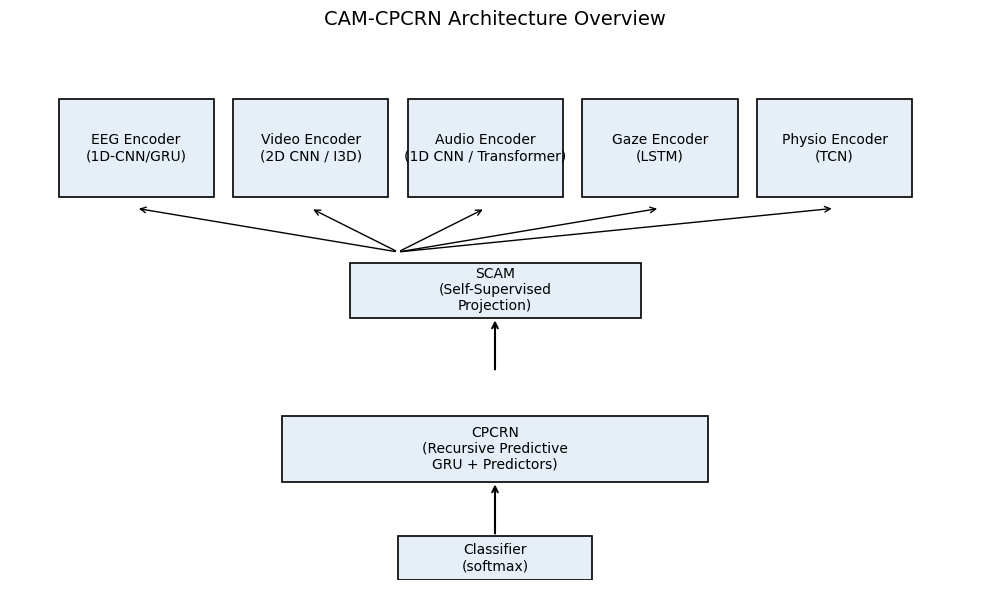

✅ Torchviz architecture diagram saved as CAM_CPCRN_model_architecture.png


In [ ]:
# -------------------------
# Visualize PyTorch computation graph with torchviz
# -------------------------
def visualize_torchviz(model, batch, savepath="CAM_CPCRN_model_architecture"):
    from torchviz import make_dot

    out = model(batch)
    logits = out["logits"]

    # Create graph
    dot = make_dot(
        logits,
        params=dict(model.named_parameters())
    )

    dot.format = "png"
    dot.render(savepath)

    print(f"✅ Torchviz architecture diagram saved as {savepath}.png")

# -------------------------
# quick smoke test with viz
# -------------------------
if __name__ == "__main__":
    device = torch.device('cpu')
    model = CAM_CPCRN().to(device)

    # fake batch
    B = 2
    batch = {
        "EEG": torch.randn(B, 32, 64),        # 64-sample window
        "VID": torch.randn(B, 3, 64, 64),     # single frame 64x64
        "AUD": torch.randn(B, 1, 160),        # audio segment
        "GAZE": torch.randn(B, 2),            # gaze XY
        "PHYS": torch.randn(B, 4, 64)         # physio channels
    }

    out = model(batch)
    print("Logits shape:", out["logits"].shape)

    # Plot block diagram (your custom overview)
    plot_architecture()

    # Plot detailed PyTorch computation graph
    visualize_torchviz(model, batch)


✅ Dataset loaded
Subjects: 28
Train shape: (14244, 128, 128, 1)  Test shape: (1583, 128, 128, 1)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step
Final training set size: (14744, 128, 128, 1) (14744,)
Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


891/891 ━━━━━━━━━━━━━━━━━━━━ 38s 38ms/step - accuracy: 0.1575 - loss: 2.9353 - val_accuracy: 0.7713 - val_loss: 0.8506
Epoch 2/100
891/891 ━━━━━━━━━━━━━━━━━━━━ 29s 33ms/step - accuracy: 0.6338 - loss: 1.2358 - val_accuracy: 0.8762 - val_loss: 0.4348
Epoch 3/100
891/891 ━━━━━━━━━━━━━━━━━━━━ 29s 33ms/step - accuracy: 0.7858 - loss: 0.7493 - val_accuracy: 0.9286 - val_loss: 0.2753
Epoch 4/100
891/891 ━━━━━━━━━━━━━━━━━━━━ 29s 32ms/step - accuracy: 0.8440 - loss: 0.5347 - val_accuracy: 0.9438 - val_loss: 0.2318
Epoch 5/100
891/891 ━━━━━━━━━━━━━━━━━━━━ 29s 32ms/step - accuracy: 0.8708 - loss: 0.4383 - val_accuracy: 0.9236 - val_loss: 0.3023
Epoch 6/100
891/891 ━━━━━━━━━━━━━━━━━━━━ 29s 32ms/step - accuracy: 0.8862 - loss: 0.3949 - val_accuracy: 0.9469 - val_loss: 0.1964
Epoch 7/100
891/891 ━━━━━━━━━━━━━━━━━━━━ 29s 33ms/step - accuracy: 0.9075 - loss: 0.3211 - val_accuracy: 0.9558 - val_loss: 0.1523
Epoch 8/100
891/891 ━━━━━━━━━━━━━━━━━━━━ 29s 33ms/step - accuracy: 0.9145 - loss: 0.2878 - val_

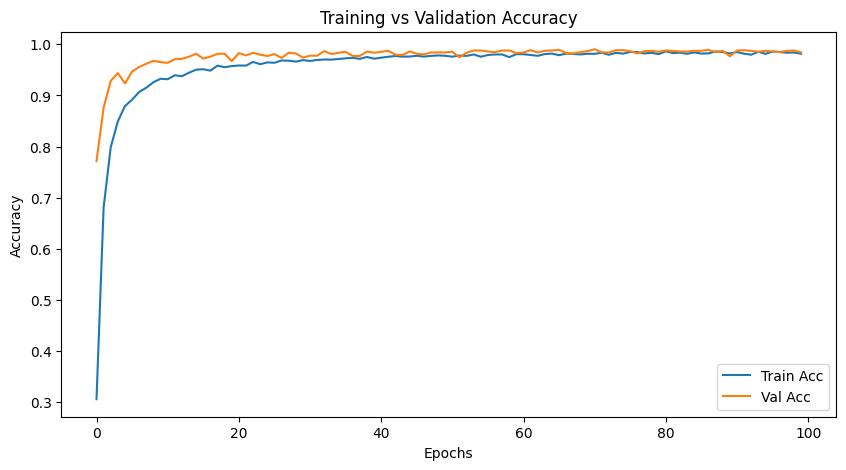

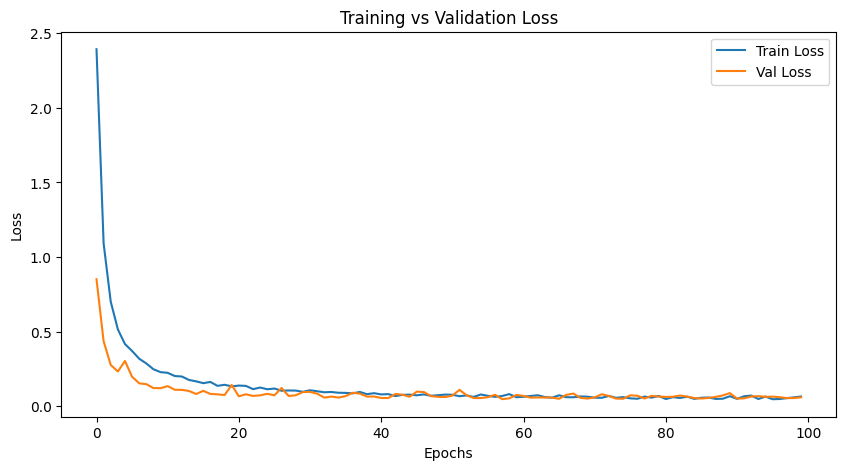


Model architecture saved as cnn_architecture.png


In [ ]:

CAM_CPCRN.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

history = CAM_CPCRN.fit(
    datagen.flow(X_train, y_train, batch_size=16),
    validation_data=(X_test, y_test),
    epochs=100,
    verbose=1
)

# ======================================
# 5. Fuzzy Rules on Confidence
# ======================================
y_pred_probs = CAM_CPCRN.predict(X_test)
confidences = np.max(y_pred_probs, axis=1)

def fuzzy_concentration(conf):
    if conf < 0.6:
        return "Low"
    elif conf < 0.85:
        return "Medium"
    else:
        return "High"

print("\nSample Predictions with Fuzzy Confidence:")
for i in range(min(5, len(X_test))):
    true_label = encoder.inverse_transform([y_test[i]])[0]
    pred_label = encoder.inverse_transform([np.argmax(y_pred_probs[i])])[0]
    print(f"True={true_label}, Pred={pred_label}, Conf={confidences[i]:.2f}, Fuzzy={fuzzy_concentration(confidences[i])}")

# ======================================
# 6. Evaluation
# ======================================
test_loss, test_acc = CAM_CPCRN.evaluate(X_test, y_test, verbose=0)
print("\nFinal CAM_CPCRN Accuracy (with GAN Augmentation):", test_acc)

# ---- Plot Training Curves ----
plt.figure(figsize=(10,5))
plt.plot(history.history['accuracy'], label="Train Acc")
plt.plot(history.history['val_accuracy'], label="Val Acc")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(10,5))
plt.plot(history.history['loss'], label="Train Loss")
plt.plot(history.history['val_loss'], label="Val Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()



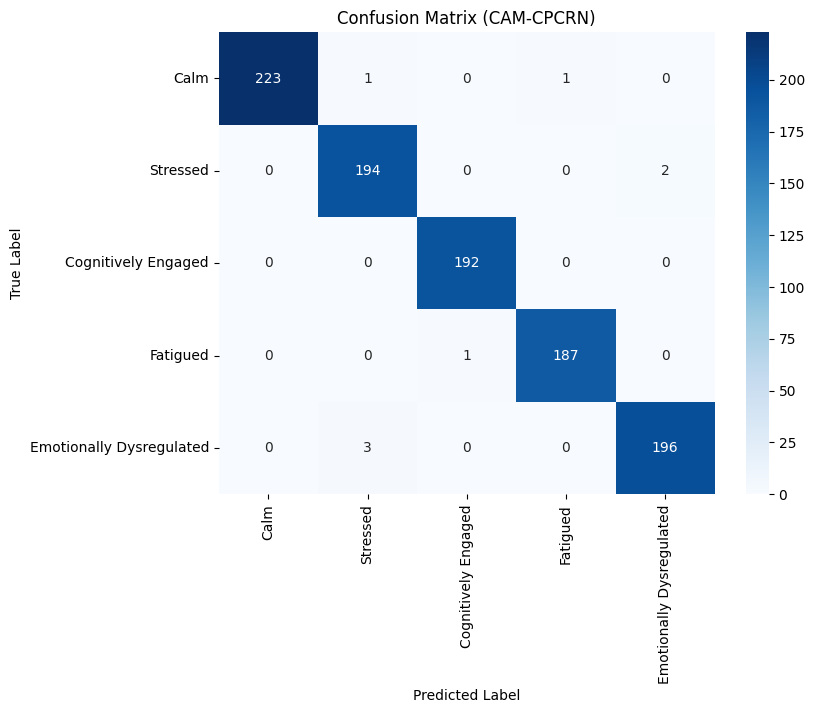

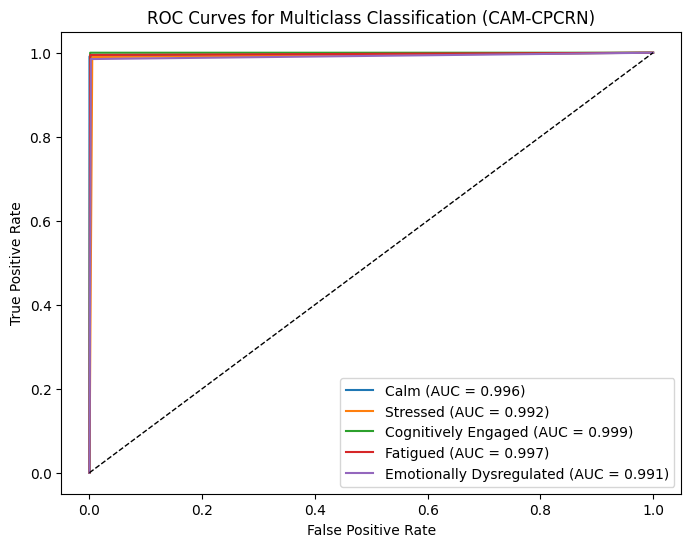

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score

# ==============================
# Setup
# ==============================
classes = ["Calm", "Stressed", "Cognitively Engaged", "Fatigued", "Emotionally Dysregulated"]

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix (CAM-CPCRN)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# ==============================
# ROC Curve (One-vs-Rest)
# ==============================
# Binarize labels
y_true_bin = label_binarize(y_true, classes=np.arange(n_classes))
y_pred_bin = label_binarize(y_pred, classes=np.arange(n_classes))

plt.figure(figsize=(8,6))
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_bin[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{classes[i]} (AUC = {roc_auc:.3f})")

plt.plot([0,1], [0,1], 'k--', lw=1)
plt.title("ROC Curves for Multiclass Classification (CAM-CPCRN)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()
